In [2]:
%%bash
pip install git+https://github.com/ishikota/PyPokerEngine.git #Git Repository

  Cloning https://github.com/ishikota/PyPokerEngine.git to /tmp/pip-req-build-sf9vf1mr
  Resolved https://github.com/ishikota/PyPokerEngine.git to commit a52a048a15da276005eca4acae96fb6eeb4dc034
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for PyPokerEngine: filename=pypokerengine-1.0.1-py3-none-any.whl size=67816 sha256=72c0abf3d99e30f5f5deee85c04c3b743693840fb980c9213fbc749f38ccb35e
  Stored in directory: /tmp/pip-ephem-wheel-cache-dw8f1j5p/wheels/3f/07/b9/6b2948370c23c711f5269c6ee6b0a24baeb64302d8541576a2
Successfully built PyPokerEngine


  Running command git clone --filter=blob:none --quiet https://github.com/ishikota/PyPokerEngine.git /tmp/pip-req-build-sf9vf1mr


In [33]:
from pypokerengine.players import BasePokerPlayer
from pypokerengine.api.game import setup_config, start_poker
from pypokerengine.utils.card_utils import gen_cards, estimate_hole_card_win_rate
import random

#Types of players (Non model)

class RandomPlayer(BasePokerPlayer):

    def declare_action(self, valid_actions, hole_card, round_state):
        actions = {a['action']: a for a in valid_actions} #Cannot raise if out of chips
        action = random.choice(list(actions.keys()))

        if action == 'raise':

            max_amount = actions[action]['amount']['max'] #Don't care for the americanised spelling
            min_amount = actions[action]['amount']['min']

            if random.random() < 0.5:
                return action, min_amount #Should prevent random from raising to high too often

            max_val = max(min_amount, max_amount - 300)
            ammount = random.randint(min_amount, max_val)

            ammount = max(ammount, min_amount) #In case max amount-300 is less than 0
            return action, ammount
        else:
            return action, actions[action]['amount'] #Call or fold

    def receive_game_start_message(self, game_info):
        pass

    def receive_round_start_message(self, round_count, hole_card, seats):
        pass

    def receive_street_start_message(self, street, round_state):
        pass

    def receive_game_update_message(self, action, round_state):
        pass

    def receive_round_result_message(self, winners, hand_info, round_state):
        pass


class HonestPlayer(BasePokerPlayer): #Modified version of HonestPlayer from Github. Instead of calling above a certain win threshold, this player will raise according to how good their hand is

    def declare_action(self, valid_actions, hole_card, round_state):

        community_card = round_state['community_card']

        win_rate = estimate_hole_card_win_rate(
            nb_simulation=100,
            nb_player=self.nb_player,
            hole_card=gen_cards(hole_card),
            community_card=gen_cards(community_card)
        )

        actions = {a['action']: a for a in valid_actions}

        if win_rate >= 1.5 / self.nb_player: #Raise when hand is strong
            if 'raise' in actions:
                return 'raise', actions['raise']['amount']['min']
            else:
                return 'call', actions['call']['amount']
        elif win_rate >= 0.8 / self.nb_player: #Call if hand okay
            return 'call', actions['call']['amount']
        else:
            return 'fold', actions['fold']['amount']

    def receive_game_start_message(self, game_info):
        self.nb_player = game_info['player_num']

    def receive_round_start_message(self, round_count, hole_card, seats):
        pass

    def receive_street_start_message(self, street, round_state):
        pass

    def receive_game_update_message(self, action, round_state):
        pass

    def receive_round_result_message(self, winners, hand_info, round_state):
        pass

class BluffPlayer(BasePokerPlayer):

    def declare_action(self, valid_actions, hole_card, round_state):

        community_card = round_state['community_card']
        win_rate = estimate_hole_card_win_rate(
            nb_simulation=100,
            nb_player=self.nb_player,
            hole_card=gen_cards(hole_card),
            community_card=gen_cards(community_card)
        )

        actions = {a['action']: a for a in valid_actions}

        if win_rate < 0.8 / self.nb_player: #Bluff weak hands to scare off other players
            if 'raise' in actions:
                return 'raise', actions['raise']['amount']['min']
            else:
                return 'call', actions['call']['amount']
        else:
            return 'call', actions['call']['amount'] #Call on good hands

    def receive_game_start_message(self, game_info):
        self.nb_player = game_info['player_num']

    def receive_round_start_message(self, round_count, hole_card, seats):
        pass

    def receive_street_start_message(self, street, round_state):
        pass

    def receive_game_update_message(self, action, round_state):
        pass

    def receive_round_result_message(self, winners, hand_info, round_state):
        pass

class PassivePlayer(BasePokerPlayer):

    def declare_action(self, valid_actions, hole_card, round_state):

        community_card = round_state['community_card']

        win_rate = estimate_hole_card_win_rate(
            nb_simulation=100,
            nb_player=self.nb_player,
            hole_card=gen_cards(hole_card),
            community_card=gen_cards(community_card)
        )

        actions = {a['action']: a for a in valid_actions}

        #Fold unless hand is excellent
        if win_rate >= 2.0 / self.nb_player:
            return 'call', actions['call']['amount']
        else:
            return 'fold', actions['fold']['amount']

    def receive_game_start_message(self, game_info):
        self.nb_player = game_info['player_num']

    def receive_round_start_message(self, round_count, hole_card, seats):
        pass

    def receive_street_start_message(self, street, round_state):
        pass

    def receive_game_update_message(self, action, round_state):
        pass

    def receive_round_result_message(self, winners, hand_info, round_state):
        pass

#To Do - Add more player types (No more than 10)

#Folder - Calls unless there is a raise, in which case this player panics and folds unless hand is excellent

#Tilt - Plays normally until they start losing chips, in which case, they start betting and bluffing aggressively

#Panic - Plays aggressivly until they start losing chips, in which case, they start to play more carfeully

#Caller - Allways calls


opponents_pool = [
    ("Honest", HonestPlayer()),
    ("Bluff", BluffPlayer()),
    ("Random", RandomPlayer()),
    ("Passive", PassivePlayer()),
]

In [34]:
import numpy as np
from collections import defaultdict
from pypokerengine.players import BasePokerPlayer
from pypokerengine.utils.card_utils import gen_cards, estimate_hole_card_win_rate

def _rank_to_char(self, rank: int) -> str: #Imported from card.py
        """Convert the int rank to char used by the `EvaluationCard` object."""
        return {
            2: "2",
            3: "3",
            4: "4",
            5: "5",
            6: "6",
            7: "7",
            8: "8",
            9: "9",
            10: "T",
            11: "J",
            12: "Q",
            13: "K",
            14: "A",
        }[rank]

class Agent(BasePokerPlayer):

    def __init__(self, alpha=0.1, gamma=0.85, nb_simulation=100):

        super().__init__()

        self.alpha = alpha
        self.initial_alpha = alpha
        self.gamma = gamma
        self.nb_simulation = nb_simulation
        self.round_count = 0

        #state -> action -> value
        self.q_table = defaultdict(lambda: {"fold": 0.0, "call": 0.0, "raise": 0.0})
        self.opponent_raises = defaultdict(int)
        self.opponent_history = defaultdict(lambda: {"honest_raise": 0, "bluff_raise": 0, "fold": 0})
        self.uuid_to_name = {}
        self.last_state = None
        self.last_action = None
        self.initial_chips = 0
        self.last_chips = 0

    def _get_state(self, win_rate, round_state):

        #Covert win rate ranges to discrete states
        if win_rate < 0.35:
            w = 0 #Weak hand
        elif win_rate < 0.50:
            w = 1 #Decent hand
        elif win_rate < 0.65:
            w = 2 #Good hand
        elif win_rate < 0.80:
            w = 3 #Great hand
        else:
            w = 4 #Amazing hand

        table = round_state['street'] #State of the cards on the table

        opponents = []

        for player in round_state['seats']:

            if player['uuid'] != self.uuid:

                name = self.uuid_to_name.get(player['uuid'], "Unknown")

                hist = self.opponent_history[name]

                total_raises = hist["honest_raise"] + hist["bluff_raise"]

                if total_raises == 0:
                    profile = 0

                else:

                    bluff_ratio = hist["bluff_raise"] / total_raises

                    if bluff_ratio > 0.4:
                        profile = 1 #Aggressive

                    else:
                        profile = 0

                opponents.append(profile)
                opponents.sort() #Order should not matter, just that there is 1 aggressive opponent and 1 passive

        opponents_stratagem = (opponents[0], opponents[1])

        return (w, table, opponents_stratagem)


    def declare_action(self, valid_actions, hole_card, round_state):

        community_card = round_state['community_card']

        win_rate = estimate_hole_card_win_rate(
            nb_simulation=self.nb_simulation,
            nb_player=self.nb_player,
            hole_card=gen_cards(hole_card),
            community_card=gen_cards(community_card)
        )

        state = self._get_state(win_rate, round_state) #Determine current state

        actions = {a['action']: a for a in valid_actions}

        q = self.q_table[state]
        action = {a: q[a] for a in actions.keys()} #Choose best of avaiable legal plays
        action = max(action, key=action.get)

        #Save for later q-table processing
        self.last_state = state
        self.last_action = action

        action_detail = actions[action]

        if action == 'raise':
            ammount = action_detail['amount']['min']
        else:
            ammount = action_detail['amount']

        return action, ammount

    def receive_game_start_message(self, game_info):
        self.nb_player = game_info['player_num']

        self.uuid_to_name.clear()
        for player in game_info['seats']:
            self.uuid_to_name[player['uuid']] = player['name']
            if player['uuid'] == self.uuid:
                self.initial_chips = player['stack'] #Set chips to starting value
                self.last_chips = self.initial_chips

    def receive_round_start_message(self, round_count, hole_card, seats):
        self.round_count += 1 #Update round count
        self.opponent_raises.clear() #Clear opponent raises

    def receive_street_start_message(self, street, round_state):
        pass

    def receive_game_update_message(self, action, round_state):
        player_name = self.uuid_to_name.get(action['player_uuid'], "")
        if action['player_uuid'] != self.uuid:
            if action['action'] == 'raise':
                self.opponent_raises[action['player_uuid']] += 1
            elif action['action'] == 'fold':
                self.opponent_history[player_name]["fold"] += 1

    def receive_round_result_message(self, winners, hand_info, round_state):

        community_card = round_state['community_card']

        for hand in hand_info:

            #print(hand_info) #Debug print statement to see how hand info displays

            uuid = hand['uuid']

            #Skip processing if hand is own (already recorded) or opponent folded
            if uuid != self.uuid and self.opponent_raises[uuid] > 0:

                cards = hand.get('hand', [])

                hole = cards.get('hole', [])

                hc = (hole['high'])

                lc = (hole['low'])

                hc = "S" + _rank_to_char(self, hc) #Set to arbitrary suit

                lc = "H" + _rank_to_char(self, lc) #Set to arbitrary suit

                cards = [hc, lc]

                #print(cards) #Debug print statement

                player_name = self.uuid_to_name.get(uuid, "")

                #Estimate hand strength
                strength = estimate_hole_card_win_rate(
                    nb_simulation=50, #Set lower to speed up rounds
                    nb_player=self.nb_player,
                    hole_card=gen_cards(cards),
                    community_card=gen_cards(community_card)
                )
                if strength >= 1.0 / self.nb_player: #Good hand
                    self.opponent_history[player_name]["honest_raise"] += self.opponent_raises[uuid]
                else: #Bluff
                    self.opponent_history[player_name]["bluff_raise"] += self.opponent_raises[uuid]

        chips = 0

        for player in round_state['seats']:
            if player['uuid'] == self.uuid:
                chips = player['stack'] #Set chips to current chip count
                break

        #Smooth reward to prevent q values from varying wildly from iteration to iteration
        r = (chips - self.last_chips) / 25.0

        if r > 0:
            r = r + 5.0  #Incentivise strategies that win chips
        elif chips <= 100:
            r = r - (20.0 - 0.2*(chips)) #Penalise low chip values

        q = self.q_table[self.last_state][self.last_action]

        max_q = 0.0
        for action in self.q_table[self.last_state]:
            max_q = max(max_q, self.q_table[self.last_state][action])

        q = q + self.alpha * (r + (self.gamma * max_q) - q) #q = q + a(r(s) + y(max(q(s', a)))-q)
        self.q_table[self.last_state][self.last_action] = q #Update q value table

        self.last_chips = chips #Update for next loop

In [37]:
import random
from pypokerengine.api.game import setup_config, start_poker

MAX_ROUNDS = 50
INITIAL_STACK = 1000
SMALL_BLIND_AMOUNT = 10

learned_Agent = Agent()

training_rounds = 25
#training_rounds = 50
training_rounds = 100

for game in range(training_rounds):

    selected_opponents = random.sample(opponents_pool, 2)
    config = setup_config(max_round=MAX_ROUNDS, initial_stack=INITIAL_STACK, small_blind_amount=SMALL_BLIND_AMOUNT)
    config.register_player(name="Agent", algorithm=learned_Agent)

    for name, obj in selected_opponents:
        config.register_player(name=name, algorithm=obj)

    start_poker(config, verbose=0)

    if game == 0 or game == (training_rounds-1) or (game+1) % 10 == 0: #Print every 10 rounds so you can know approx how far into training (As well as first and last rounds) Change value from 10 to a higher number if doing 500+ tests
        opponent_names = [name for name, _ in selected_opponents]
        print(f"Game {game+1}/{training_rounds} finished - Opponents: {opponent_names[0], opponent_names[1]} - Chips: {learned_Agent.last_chips}")

Game 1/100 finished - Opponents: ('Honest', 'Random') - Chips: 1456
Game 10/100 finished - Opponents: ('Passive', 'Random') - Chips: 2633
Game 20/100 finished - Opponents: ('Bluff', 'Random') - Chips: 0
Game 30/100 finished - Opponents: ('Bluff', 'Random') - Chips: 2988
Game 40/100 finished - Opponents: ('Bluff', 'Random') - Chips: 0
Game 50/100 finished - Opponents: ('Random', 'Bluff') - Chips: 10
Game 60/100 finished - Opponents: ('Passive', 'Random') - Chips: 2151
Game 70/100 finished - Opponents: ('Honest', 'Bluff') - Chips: 650
Game 80/100 finished - Opponents: ('Passive', 'Honest') - Chips: 2260
Game 90/100 finished - Opponents: ('Passive', 'Bluff') - Chips: 1210
Game 100/100 finished - Opponents: ('Random', 'Bluff') - Chips: 2995


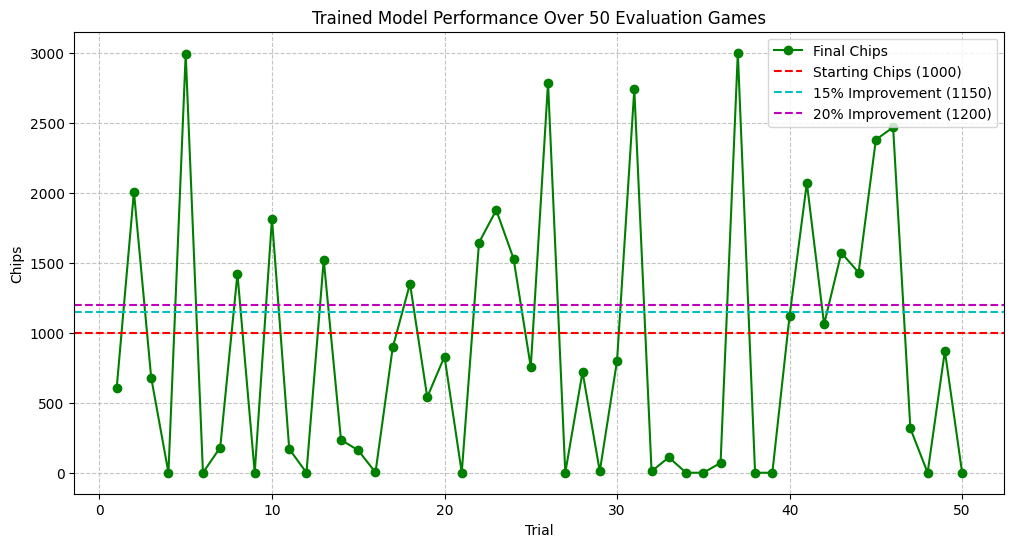

In [38]:
import matplotlib.pyplot as plt
import random
from pypokerengine.api.game import setup_config, start_poker

chips = []

game_count = 25
game_count = 50


for game in range(game_count):
    opponents = random.sample(opponents_pool, 2)

    #Display opponents per round so we can see which opponents the Agent struggles with
    #for name, _ in opponents:
    #    print(name)
    #print("")

    config = setup_config(max_round=MAX_ROUNDS, initial_stack=INITIAL_STACK, small_blind_amount=SMALL_BLIND_AMOUNT)
    config.register_player(name="Agent", algorithm=learned_Agent)

    for name, alg in opponents:
        config.register_player(name=name, algorithm=alg)

    start_poker(config, verbose=0)

    chips.append(learned_Agent.last_chips)


plt.figure(figsize=(12, 6))
plt.plot(range(1, game_count+1), chips, marker='o', linestyle='-', color='g', label='Final Chips')
plt.axhline(y=1000, color='r', linestyle='--', label='Starting Chips (1000)')
plt.axhline(y=1150, color='c', linestyle='--', label='15% Improvement (1150)')
plt.axhline(y=1200, color='m', linestyle='--', label='20% Improvement (1200)')
plt.title("Trained Model Performance Over " + str(game_count) + " Evaluation Games")
plt.xlabel("Trial")
plt.ylabel("Chips")
plt.grid(True, linestyle='--', alpha=0.75)
plt.legend()
plt.show()

#To Do - Calculate average chip improvement over games
#Should probably do in another cell so you don't have to run the eval games every time
#Track performance against each player type?

